# Análisis Avanzado de Datos & Modelado
**Institución:** Universidad Católica Boliviana "San Pablo"  
**Programa:** Maestría en Ciencia de Datos  
**Autor:** Carlos Andrés Pérez Guzmán  
**Fecha:** Junio 2026  

---
### ⚙️ Entorno y Objetivos del Notebook
> **Nota:** Este cuaderno implementa una prueba de concepto para el proyecto de segunda fase en laMaestrái de Ciencia de Datos.

* **Fase del Proyecto:** Prueba de concepto
* **Core Tech Stack:** `Python` (Programación general para ciencia de datos)
---

<h3><span style="color:#05856d">1. Librerías</span></h3>

---

In [ ]:
# Manupulación de datos y cálculos
import polars as pl
import polars.selectors as cs

<h3><span style="color:#05856d">2. Carga y limpieza de información</span></h3>

---

In [53]:
from s_01_functions import load_data_own, limpiar_texto_own

df = (
    load_data_own( file_path_param = 'iowa_liquor_sales_2026_1263_rows.csv')

    .with_columns(
        limpiar_texto_own(column_param = cs.string() - cs.by_name('ordered_on')),
        pl.col('ordered_on').str.to_date(format = '%Y-%m-%d')
        )
    .with_columns(
        pl.col('im_desc','category_name').cast(dtype = pl.Categorical())
        )

    )

df.glimpse()

📦 Iniciando carga de datos locales desde: iowa_liquor_sales_2026_1263_rows.csv
✅ Carga completada: 964947 registros en 0.34 segundos.


KeyboardInterrupt: 

<h3><span style="color:#05856d">3. Selección de variables</span></h3>

---

Es importante identificar qué variables tienen alguna funcionalidad estratégica al construir un modelo de decisión

In [ ]:
# Variables con utilidad estratégica
df_selected_variables = [
    'ordered_on','item_no','im_desc','category_name','sales_bottles',
    'sales_dollars','pack','bottle_volume_ml']

# Variables sin utilidad estratégica
df_eliminated_variables = set(df.columns) - set(df_selected_variables)
print("Variables sin utilidad estratégica:\n", *sorted(df_eliminated_variables), sep='\n')

Variables sin utilidad estratégica:

category_code
county_fips_code
county_name
invoice_id
sales_gallons
sales_liters
store_address
store_city
store_name
store_no
store_zip_code
vendor_name
vendor_number


In [ ]:
# Seleccionar variables de interés
df_01 = df.select(df_selected_variables)
df_01.glimpse()

# Eliminar variables intermedias
del df, df_selected_variables, df_eliminated_variables, limpiar_texto_own, load_data_own

Rows: 964947
Columns: 8
$ ordered_on       <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ item_no           <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ sales_bottles     <f64> 2.0, 6.0, 7.0, 2.0, 12.0, 8.0, 7.0, 2.0, 2.0, 2.0
$ sales_dollars     <f64> 34.5, 103.5, 34.16, 17.28, 225.0, 42.0, 68.25, 34.5, 34.5, 21.0
$ pack              <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ bottle_volume_ml  <f64> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 75

La llave que le da identidad a un producto es la combinación de item_no y im_desc

In [ ]:
df_01.select('item_no','im_desc').unique().select('im_desc').is_duplicated().any()

True

In [ ]:
df_01.select('item_no','im_desc').unique().select('item_no').is_duplicated().any()

True

In [ ]:
df_01.select('item_no','im_desc').unique().is_duplicated().any()

False

¿Existen productos con más de una categoría?

Sí, existen prodcutos con más de una categoría

In [ ]:
df_01.select('category_name','item_no','im_desc').unique().is_duplicated().any()

False

In [ ]:
(
    df_01.select('category_name', 'item_no', 'im_desc')
    .unique()
    # Mantenemos las 3 columnas, pero contamos si el par (item, desc) se repite más de 1 vez
    .filter(pl.len().over('item_no', 'im_desc') > 1)
    .sort('item_no','category_name')
)

category_name,item_no,im_desc
cat,i64,cat
"""SCOTCH WHISKIES""",6768,"""LAGAVULIN SWEET PEAT"""
"""TEMPORARY & SPECIALTY PACKAGES""",6768,"""LAGAVULIN SWEET PEAT"""
"""SINGLE MALT SCOTCH""",7224,"""MACALLAN SHERRY OAK 12YO 110 P…"
"""TEMPORARY & SPECIALTY PACKAGES""",7224,"""MACALLAN SHERRY OAK 12YO 110 P…"
"""IRISH WHISKIES""",14812,"""JAMESON ORIGINAL MLS SPECIAL E…"
…,…,…
"""TEMPORARY & SPECIALTY PACKAGES""",73985,"""EVAN WILLIAMS BLACKBERRY MINI"""
"""CREAM LIQUEURS""",80276,"""JACKSON MORGAN SOUTHERN CREAM …"
"""TEMPORARY & SPECIALTY PACKAGES""",80276,"""JACKSON MORGAN SOUTHERN CREAM …"


<h3><span style="color:#05856d">4. Análisis exploratorio</span></h3>

---

¿Qué producto vendió más botellas?

In [ ]:
analysis_01 = (
    df_01
    .group_by('item_no','im_desc')
    .agg(pl.sum('sales_bottles').alias('count'))
    .sort( by = 'count', descending = True)
    )

print(f"Existen {analysis_01.n_unique(subset = ['item_no','im_desc'])} productos en el dataset.")
analysis_01.show()

Existen 4048 productos en el dataset.
shape: (5, 3)
┌─────────┬─────────────────────────────────┬──────────┐
│ item_no ┆ im_desc                         ┆ count    │
│ ---     ┆ ---                             ┆ ---      │
│ i64     ┆ cat                             ┆ f64      │
╞═════════╪═════════════════════════════════╪══════════╡
│ 64870   ┆ FIREBALL CINNAMON WHISKEY       ┆ 953182.0 │
│ 65013   ┆ FIREBALL CINNAMON WHISKEY MINI… ┆ 361013.0 │
│ 36904   ┆ MCCORMICK 80PRF VODKA PET       ┆ 252071.0 │
│ 38177   ┆ TITOS HANDMADE VODKA            ┆ 195662.0 │
│ 84171   ┆ 99 BANANAS                      ┆ 188879.0 │
└─────────┴─────────────────────────────────┴──────────┘


¿Qué categoría generó más ganacias?

In [ ]:
analysis_02 = (
    df_01
    .group_by('category_name')
    .agg( (pl.sum('sales_dollars')/1e6).alias('count_M') )
    .sort( by = 'count_M', descending = True)
    )

print(f"Existen {analysis_02.n_unique(subset = 'category_name')} categorías únicas en el dataset.")
analysis_02.show()

Existen 44 categorías únicas en el dataset.
shape: (5, 2)
┌───────────────────────────┬───────────┐
│ category_name             ┆ count_M   │
│ ---                       ┆ ---       │
│ cat                       ┆ f64       │
╞═══════════════════════════╪═══════════╡
│ AMERICAN VODKAS           ┆ 25.500022 │
│ CANADIAN WHISKIES         ┆ 17.243223 │
│ STRAIGHT BOURBON WHISKIES ┆ 15.29209  │
│ 100% AGAVE TEQUILA        ┆ 12.68607  │
│ WHISKEY LIQUEUR           ┆ 10.740141 │
└───────────────────────────┴───────────┘


Productos de mayor importancia por frecuencia de damanda

In [ ]:
analysis_03 = (
    df_01
    .group_by(['item_no', 'im_desc'])
    .agg(
        # 1. ¿Cuántas botellas se han vendido en la historia de este producto?
        pl.sum('sales_bottles').alias('volumen_total'),
        
        # 2. ¿En cuántos días únicos alguien compró al menos 1 botella?
        pl.n_unique('ordered_on').alias('frecuencia_dias_demanda')
    )
    # Remover elementos raros (productos que quizá se venden mucho pero solo en 2 días del año)
    .filter(pl.col("frecuencia_dias_demanda") > 100)
    
    # Ordenamos por los que tienen demanda más constante, y luego por volumen
    .sort(["frecuencia_dias_demanda", "volumen_total"], descending = [True, True])
)

analysis_03.show(10)

shape: (10, 4)
┌─────────┬─────────────────────────────────┬───────────────┬─────────────────────────┐
│ item_no ┆ im_desc                         ┆ volumen_total ┆ frecuencia_dias_demanda │
│ ---     ┆ ---                             ┆ ---           ┆ ---                     │
│ i64     ┆ cat                             ┆ f64           ┆ u32                     │
╞═════════╪═════════════════════════════════╪═══════════════╪═════════════════════════╡
│ 36904   ┆ MCCORMICK 80PRF VODKA PET       ┆ 252071.0      ┆ 115                     │
│ 38177   ┆ TITOS HANDMADE VODKA            ┆ 195662.0      ┆ 115                     │
│ 11788   ┆ BLACK VELVET                    ┆ 159974.0      ┆ 115                     │
│ 48254   ┆ HENNESSY VS FLASK               ┆ 35671.0       ┆ 115                     │
│ 34456   ┆ KETEL ONE                       ┆ 11455.0       ┆ 115                     │
│ 64870   ┆ FIREBALL CINNAMON WHISKEY       ┆ 953182.0      ┆ 114                     │
│ 65013   ┆ FIREB

<h3><span style="color:#05856d">5. Resampling e imputación de 0's</span></h3>

---

El seleccionado para la simulación es **MCCORMICK 80PRF VODKA PET (Item No: 36904)**.En 115 días distintos se ha vendido más de 250,000 botellas. Entonces, al aislar McCormick, se sumarán todas sus ventas por día (porque en un día puede haber sido comprado por 50 tiendas distintas) y, lo más crítico: se crearán los días en los que no se vendió nada para colcarles Demanda = 0.

In [54]:
# 1. Filtrar y agrupar el producto tipo
analysis_04 = (
    df_01
    .filter((pl.col('item_no') == 36904) & 
            (pl.col('im_desc') == 'MCCORMICK 80PRF VODKA PET') )
    .group_by('ordered_on')
    .agg(
        pl.sum('sales_bottles').alias('demanda_diaria'),
        pl.sum('sales_dollars').alias('ingresos_diarios') )
)

# 2 Imputación estocástica de ceros (0's)

aux_calendario = pl.DataFrame({
    'ordered_on': pl.date_range(
        start = pl.date(year = 2026, month = 1, day = 1),
        end = analysis_04['ordered_on'].max(),
        interval = '1d',
        eager = True)
})

analysis_05 = (
    aux_calendario
    .join(analysis_04, on = 'ordered_on', how = 'left', validate = '1:1')
    .with_columns([
        # Si ese día no hubo ventas, la demanda y el ingreso son 0
        pl.col('demanda_diaria').fill_null(0),
        pl.col('ingresos_diarios').fill_null(0.0)
    ])
)

print(f"Días totales de simulación: {analysis_05.height}")
analysis_05.head(10)

Días totales de simulación: 150


ordered_on,demanda_diaria,ingresos_diarios
date,f64,f64
2026-01-01,0.0,0.0
2026-01-02,1741.0,4782.0
2026-01-03,0.0,0.0
2026-01-04,576.0,1584.0
2026-01-05,3031.0,8332.0
2026-01-06,2201.0,6050.0
2026-01-07,1082.0,2971.0
2026-01-08,1588.0,4365.0
2026-01-09,2400.0,6596.0


Si se estudia el resultado, es probable observar algunos días con demanda_diaria = 0. Si no hiciéramos este paso de rellenar los ceros, el agente de AI (Deep Reinforcement Learning) creería que todos los días se vende producto. Al poner los ceros, el agente aprenderá por las malas que si pide mucho inventario en un día malo, se quedará con el producto estancado y se le cobrarán costos de almacenamiento (Holding Costs).

<h3><span style="color:#05856d">6. Parámetros del entorno (MDP Constantes)</span></h3>

---

Una vez generada la serie de tiempo continua, se deben definir las constantes físicas y financieras que regirán la simulación logística:

- **Precio de Venta ($p$)**: Calculado dinámicamente como $\sum Ingresos / \sum Demanda$. Representa el flujo de caja de entrada.

- **Tamaño del Lote ($pack$)**: Extraído del registro original del producto seleccionado. El agente no pedirá botellas sueltas, pedirá "cajas". Su acción $A_t = 1$ sumará el valor de un $pack$ al inventario.

- **Costo de Mantenimiento / Holding Cost ($h$)**: Penalización impuesta por cada unidad de producto no vendida que permanece en el almacén al final del día.

- **Costo por Quiebre de Stock / Stockout Cost ($k$)**: Penalización aplicada al agente si la demanda es mayor a su inventario (ventas perdidas / pérdida de buena voluntad del cliente).

- **Lead Time ($L$)**: El retraso de tiempo entre que el agente decide hacer un pedido a la destilería y el momento en que las botellas llegan físicamente al almacén para poder ser despachadas.

In [ ]:
df_01.glimpse()

Rows: 964947
Columns: 8
$ ordered_on       <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ item_no           <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ sales_bottles     <f64> 2.0, 6.0, 7.0, 2.0, 12.0, 8.0, 7.0, 2.0, 2.0, 2.0
$ sales_dollars     <f64> 34.5, 103.5, 34.16, 17.28, 225.0, 42.0, 68.25, 34.5, 34.5, 21.0
$ pack              <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ bottle_volume_ml  <f64> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 75

In [ ]:
aux_parametros_entorno = (
    df_01
    .filter((pl.col('item_no') == 36904) & 
            (pl.col('im_desc') == 'MCCORMICK 80PRF VODKA PET') )
    .select([

        # Precio de venta promedio por botella
        ( (pl.col('sales_dollars').sum()) / (pl.col('sales_bottles').sum()) ).alias('precio_unitario_promedio'),
        
        # Tamaño de la caja (pack) - usualmente es el mismo para todo el producto
        pl.col('pack').first().alias('unidades_por_caja')
    ])
)

print(aux_parametros_entorno)

shape: (1, 2)
┌──────────────────────────┬───────────────────┐
│ precio_unitario_promedio ┆ unidades_por_caja │
│ ---                      ┆ ---               │
│ f64                      ┆ i64               │
╞══════════════════════════╪═══════════════════╡
│ 2.757891                 ┆ 24                │
└──────────────────────────┴───────────────────┘


<h3><span style="color:#05856d">7. Ejecución de la prueba</span></h3>

---

In [ ]:
# =========================================================================================================
# EVALUACIÓN TRADICIONAL EN ENTORNO IDEAL
# =========================================================================================================

from s_02_entorno_ideal import IowaLiquorEnvIdeal
from s_01_functions import AgenteMinMaxIdeal, evaluar_agente

# 1. Recuperar las unidades por caja del análisis previo
unidades_caja = int(aux_parametros_entorno['unidades_por_caja'][0])

# 2. Instanciar el entorno ideal calibrado (300 cajas de capacidad)
env_ideal = IowaLiquorEnvIdeal(df_episodio=analysis_05, capacidad_max_cajas=300)

# 3. Configurar el agente con los mismos parámetros de la calibración tradicional
agente_ideal = AgenteMinMaxIdeal(
    punto_reorden=2500,     
    nivel_maximo=7000,      
    unidades_por_caja=unidades_caja
)

# 4. Ejecutar la evaluación del escenario base ideal
print("📈 Iniciando Simulación: Escenario Ideal de Control (Sin Incertidumbre)...")
historial_ideal = evaluar_agente(env_ideal, agente_ideal, num_episodios=1)

📈 Iniciando Simulación: Escenario Ideal de Control (Sin Incertidumbre)...
📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $236,995.61
🚨 Días con Quiebre de Stock: 84 días
--------------------------------------------------


In [ ]:
from s_01_functions import AgenteMinMaxBolivia, evaluar_agente
from s_02_entorno_est import EntornoBolivia

# 1. Recuperamos las unidades por caja del análisis previo
unidades_caja = int(aux_parametros_entorno['unidades_por_caja'][0])

# 2. Instanciamos el entorno con el nuevo motor de Markov
env_markov = EntornoBolivia(df_episodio=analysis_05, capacidad_max_cajas=300)

# 3. Configuramos al agente con un punto de reorden alto (colchón de seguridad)
agente_caos = AgenteMinMaxBolivia(
    punto_reorden=3500, 
    nivel_maximo=7000,  
    unidades_por_caja=unidades_caja
)

# 4. Ejecutamos la evaluación de la política tradicional
print("🇧🇴 Iniciando Simulación con Motor de Markov (Ráfagas de Bloqueos)...")
historial_caos = evaluar_agente(env_markov, agente_caos, num_episodios=1)


🇧🇴 Iniciando Simulación con Motor de Markov (Ráfagas de Bloqueos)...
📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $-240,757.90
🚨 Días con Quiebre de Stock: 89 días
--------------------------------------------------


In [ ]:
# =========================================================================================================
# ENTRENAMIENTO DE LA INTELIGENCIA ARTIFICIAL (DRL - PPO)
# =========================================================================================================

from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from s_02_entorno_est import EntornoBolivia

# 1. Función para instanciar nuestro entorno caótico
def make_env():
    return EntornoBolivia(df_episodio=analysis_05, capacidad_max_cajas=300)

# Stable-Baselines3 requiere "vectorizar" el entorno para optimizar la memoria y CPU
vec_env = make_vec_env(make_env, n_envs=1)

# 2. Instanciamos el algoritmo PPO (La Red Neuronal)
# - policy="MlpPolicy": Perceptrón Multicapa (arquitectura clásica de red neuronal para variables numéricas)
# - verbose=1: Para que nos imprima en pantalla cómo va aprendiendo
modelo_ppo = PPO(
    policy="MlpPolicy", 
    env=vec_env, 
    learning_rate=0.0003, # Tasa de aprendizaje estándar en PPO
    verbose=1 
)

# 3. Fase de Entrenamiento (Trial & Error)
print("🧠 Iniciando Entrenamiento de la IA (PPO)...")

# Lo pondremos a vivir la simulación por 50,000 pasos (días virtuales)
# Esto equivale a vivir la serie de tiempo de 150 días unas 333 veces.
modelo_ppo.learn(total_timesteps=50000)

print("✅ Entrenamiento Finalizado.")

Using cpu device
🧠 Iniciando Entrenamiento de la IA (PPO)...
----------------------------------
| rollout/           |           |
|    ep_len_mean     | 150       |
|    ep_rew_mean     | -3.68e+05 |
| time/              |           |
|    fps             | 926       |
|    iterations      | 1         |
|    time_elapsed    | 2         |
|    total_timesteps | 2048      |
----------------------------------
-------------------------------------------
| rollout/                |               |
|    ep_len_mean          | 150           |
|    ep_rew_mean          | -3.6e+05      |
| time/                   |               |
|    fps                  | 705           |
|    iterations           | 2             |
|    time_elapsed         | 5             |
|    total_timesteps      | 4096          |
| train/                  |               |
|    approx_kl            | 1.0101066e-06 |
|    clip_fraction        | 0             |
|    clip_range           | 0.2           |
|    entropy_loss

In [ ]:
# =========================================================================================================
# EVALUACIÓN DE LA INTELIGENCIA ARTIFICIAL
# =========================================================================================================

# 1. Creamos un "Envoltorio" para que la IA se comporte como nuestros agentes anteriores
class AgentePPO_Wrapper:
    def __init__(self, modelo_entrenado):
        self.modelo = modelo_entrenado
        
    def predecir(self, observacion: np.ndarray) -> int:
        # El parámetro deterministic=True hace que la IA use lo que aprendió en lugar de adivinar
        accion, _ = self.modelo.predict(observacion, deterministic=True)
        return int(accion)

# 2. Instanciamos el agente envolviendo al modelo que acabas de entrenar
agente_ia_novato = AgentePPO_Wrapper(modelo_ppo)

# 3. Lo evaluamos en un entorno nuevo para ver su desempeño real
env_prueba_ia = EntornoBolivia(df_episodio=analysis_05, capacidad_max_cajas=300)

print("🤖 Iniciando Simulación: Agente PPO (50k pasos) vs Entorno de Markov...")
historial_ia = evaluar_agente(env_prueba_ia, agente_ia_novato, num_episodios=1)

🤖 Iniciando Simulación: Agente PPO (50k pasos) vs Entorno de Markov...
📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $-180,100.85
🚨 Días con Quiebre de Stock: 74 días
--------------------------------------------------


In [ ]:
# =========================================================================================================
# ENTRENAMIENTO MAESTRO (1 MILLÓN DE PASOS PARALELIZADOS)
# =========================================================================================================

import time
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env

# 1. Vectorización Extrema: 8 entornos viviendo simulaciones paralelas
vec_env_master = make_vec_env(make_env, n_envs=8)

# 2. Instanciamos el modelo con parámetros optimizados
modelo_ppo_master = PPO(
    policy="MlpPolicy", 
    env=vec_env_master, 
    learning_rate=0.0003,
    n_steps=2048,
    batch_size=64,
    ent_coef=0.01, # Ajuste fino para forzar a la IA a converger más rápido
    verbose=0 # Consola apagada para maximizar rendimiento de CPU
)

print("🚀 Iniciando Entrenamiento Maestro (1,000,000 de pasos)...")
inicio = time.time()

# 3. Lanzamos el entrenamiento pesado
modelo_ppo_master.learn(total_timesteps=1_000_000)

fin = time.time()
print(f"✅ Entrenamiento completado en {(fin - inicio) / 60:.2f} minutos.")

# 4. Evaluación del Agente Experto
agente_ia_master = AgentePPO_Wrapper(modelo_ppo_master)

print("-" * 50)
print("🏆 Iniciando Simulación Definitiva: Agente PPO EXPERTO vs Entorno de Markov...")
historial_ia_master = evaluar_agente(env_prueba_ia, agente_ia_master, num_episodios=1)

🚀 Iniciando Entrenamiento Maestro (1,000,000 de pasos)...
✅ Entrenamiento completado en 10.39 minutos.
--------------------------------------------------
🏆 Iniciando Simulación Definitiva: Agente PPO EXPERTO vs Entorno de Markov...
📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $-66,639.91
🚨 Días con Quiebre de Stock: 66 días
--------------------------------------------------


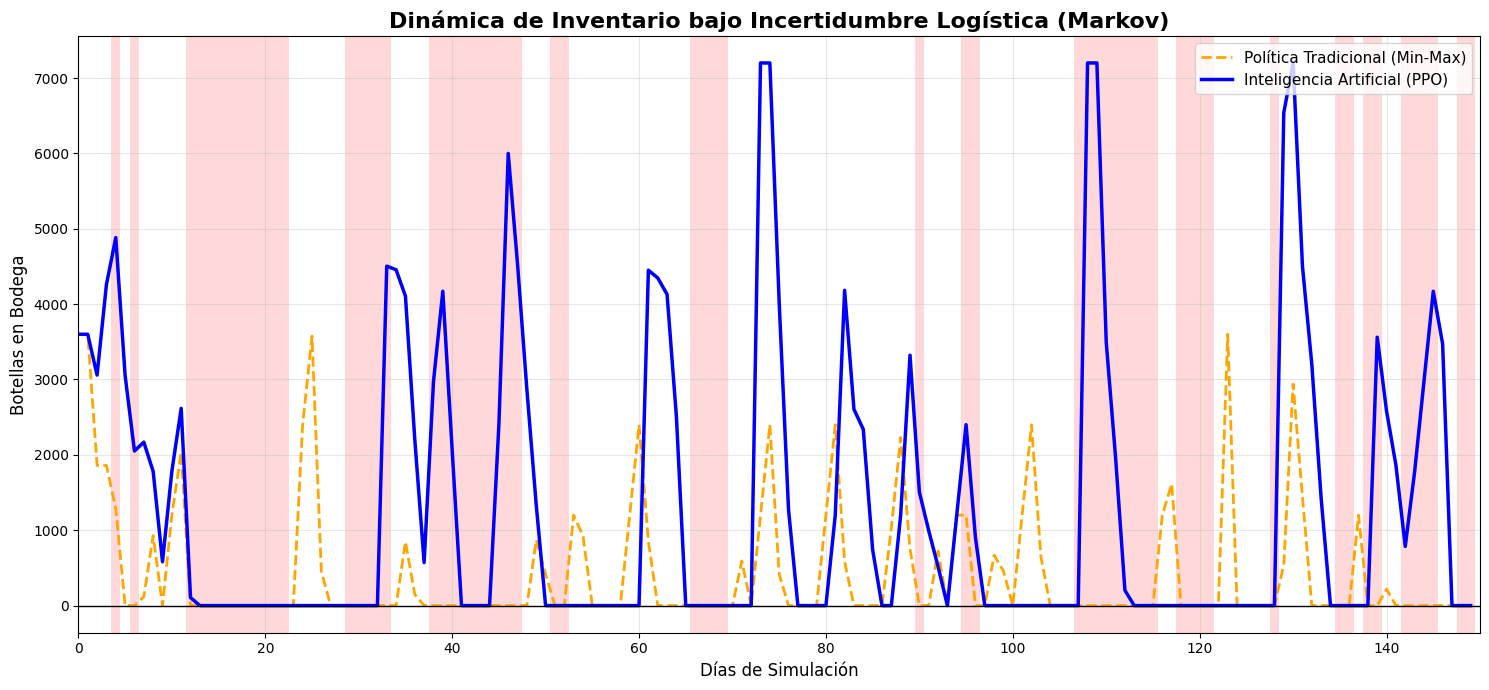

In [ ]:
# =========================================================================================================
# VISUALIZACIÓN COMPARATIVA: IA vs HUMANO
# =========================================================================================================

import matplotlib.pyplot as plt
import numpy as np

def rastrear_episodio(env, agente, es_ia=False):
    """Ejecuta un episodio y guarda el registro diario de inventario y bloqueos."""
    obs, _ = env.reset()
    terminado = False
    
    historial_inventario = []
    historial_bloqueos = []
    
    while not terminado:
        # Extraer estado del bloqueo actual (índice 2 de la observación)
        estado_bloqueo = obs[2] 
        historial_bloqueos.append(estado_bloqueo)
        historial_inventario.append(obs[0])
        
        if es_ia:
            accion, _ = agente.modelo.predict(obs, deterministic=True)
            accion = int(accion)
        else:
            accion = agente.predecir(obs)
            
        obs, recompensa, terminado, truncado, info = env.step(accion)
        
    return np.array(historial_inventario), np.array(historial_bloqueos)

# 1. Rastrear al Administrador Tradicional
env_rastreo_humano = EntornoBolivia(df_episodio=analysis_05, capacidad_max_cajas=300)
inv_humano, bloqueos = rastrear_episodio(env_rastreo_humano, agente_caos, es_ia=False)

# 2. Rastrear a la Inteligencia Artificial (Experta)
env_rastreo_ia = EntornoBolivia(df_episodio=analysis_05, capacidad_max_cajas=300)
inv_ia, _ = rastrear_episodio(env_rastreo_ia, agente_ia_master, es_ia=True)

# 3. Graficar los resultados
dias = np.arange(len(inv_humano))

plt.figure(figsize=(15, 7))

# Sombreado rojo para los días con bloqueo de carreteras
for d in dias:
    if bloqueos[d] == 1:
        plt.axvspan(d-0.5, d+0.5, color='red', alpha=0.15, lw=0)

# Curvas de Inventario
plt.plot(dias, inv_humano, label='Política Tradicional (Min-Max)', color='orange', linestyle='--', linewidth=2)
plt.plot(dias, inv_ia, label='Inteligencia Artificial (PPO)', color='blue', linewidth=2.5)

# Línea de Quiebre de Stock
plt.axhline(0, color='black', linewidth=1)

plt.title('Dinámica de Inventario bajo Incertidumbre Logística (Markov)', fontsize=16, fontweight='bold')
plt.xlabel('Días de Simulación', fontsize=12)
plt.ylabel('Botellas en Bodega', fontsize=12)
plt.legend(loc='upper right', fontsize=11)
plt.grid(alpha=0.3)
plt.xlim(0, 150)

plt.tight_layout()
plt.show()

In [ ]:
# =========================================================================================================
# RE-ENTRENAMIENTO CON CAPACIDAD AMPLIADA (100 CAJAS)
# =========================================================================================================

# 1. Definimos la nueva configuración
def make_env_100():
    return EntornoBolivia(df_episodio=analysis_05, capacidad_max_cajas=100)

# 2. Vectorización y creación del modelo
vec_env_100 = make_vec_env(make_env_100, n_envs=8)

modelo_ppo_100 = PPO(
    policy="MlpPolicy", 
    env=vec_env_100, 
    learning_rate=0.0003,
    verbose=0 
)

# 3. Entrenamiento (lo haremos rápido, 500k pasos son suficientes para ver la diferencia)
print("🚀 Entrenando con capacidad de 100 cajas...")
modelo_ppo_100.learn(total_timesteps=500_000)

# 4. Evaluación
agente_ia_100 = AgentePPO_Wrapper(modelo_ppo_100)
env_prueba_100 = EntornoBolivia(df_episodio=analysis_05, capacidad_max_cajas=100)

print("-" * 50)
print("🏆 Resultados con Capacidad de 100 Cajas:")
historial_ia_100 = evaluar_agente(env_prueba_100, agente_ia_100, num_episodios=1)

🚀 Entrenando con capacidad de 100 cajas...
--------------------------------------------------
🏆 Resultados con Capacidad de 100 Cajas:
📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $-420,340.57
🚨 Días con Quiebre de Stock: 105 días
--------------------------------------------------


In [ ]:
# =========================================================================================================
# WARM START: APRENDIZAJE BASADO EN EL EXPERTO HUMANO
# =========================================================================================================

from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3 import PPO

# 1. Definimos el agente experto (el que mejor nos ha funcionado hasta ahora)
# Usaremos los parámetros que ya validamos como "base"
agente_experto = AgenteMinMaxBolivia(
    punto_reorden=3500, 
    nivel_maximo=7000,  
    unidades_por_caja=100 # Acorde a nuestra nueva configuración física
)

# 2. Creamos una función para "imitar" al humano
def train_warm_start(env, num_steps=100_000):
    model = PPO("MlpPolicy", env, verbose=0)
    
    # Aquí forzamos al modelo a tomar las decisiones del humano durante la exploración
    obs, _ = env.reset()
    for _ in range(num_steps):
        # El modelo consulta al humano
        accion = agente_experto.predecir(obs)
        # El modelo aprende de esa acción
        action, _states = model.predict(obs, deterministic=False)
        obs, rewards, dones, truncated, info = env.step(accion)
        if dones:
            obs, _ = env.reset()
            
    return model

print("🚀 Iniciando Warm Start: La IA está estudiando al administrador humano...")
modelo_ppo_warm = train_warm_start(make_env_100(), num_steps=100_000)

# 3. Refinamiento: Ahora dejamos que la IA tome el control para superar al humano
print("🧠 Refinando la política aprendida (Fine-tuning)...")
modelo_ppo_warm.learn(total_timesteps = 400_000)

print("✅ Entrenamiento con Warm Start finalizado.")

🚀 Iniciando Warm Start: La IA está estudiando al administrador humano...
🧠 Refinando la política aprendida (Fine-tuning)...
✅ Entrenamiento con Warm Start finalizado.


In [ ]:
# =========================================================================================================
# EVALUACIÓN FINAL: EL VEREDICTO DE LA IA ESTRATEGA
# =========================================================================================================

from s_02_entorno_est import EntornoBolivia
from s_01_functions import evaluar_agente

# 1. Re-instanciamos el entorno necesario para la evaluación (100 cajas)
env_prueba_100 = EntornoBolivia(df_episodio=analysis_05, capacidad_max_cajas=100)

# 2. Re-aseguramos el Wrapper (por si el Kernel lo olvidó)
class AgentePPO_Wrapper:
    def __init__(self, modelo_entrenado):
        self.modelo = modelo_entrenado
    def predecir(self, observacion: np.ndarray) -> int:
        accion, _ = self.modelo.predict(observacion, deterministic=True)
        return int(accion)

# 3. Envolvemos el modelo maestro
agente_ia_final = AgentePPO_Wrapper(modelo_ppo_warm)

# 4. Lanzamos la evaluación final
print("🏆 Resultados Finales (IA Estratega con Warm Start):")
historial_final = evaluar_agente(env_prueba_100, agente_ia_final, num_episodios=1)

🏆 Resultados Finales (IA Estratega con Warm Start):
📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $-353,917.89
🚨 Días con Quiebre de Stock: 106 días
--------------------------------------------------


In [ ]:
# =========================================================================================================
# EXPERIMENTO FINAL: CAPACIDAD DE 150 CAJAS (3,600 UNIDADES)
# =========================================================================================================

from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from s_02_entorno_est import EntornoBolivia
from s_01_functions import evaluar_agente

# 1. Instanciamos el entorno con 150 cajas
def make_env_150():
    return EntornoBolivia(df_episodio=analysis_05, capacidad_max_cajas=150)

# 2. Entrenamos un nuevo modelo maestro
vec_env_150 = make_vec_env(make_env_150, n_envs=8)
modelo_ppo_150 = PPO("MlpPolicy", vec_env_150, verbose=0)

print("🚀 Entrenando con capacidad de 150 cajas (flota pesada)...")
modelo_ppo_150.learn(total_timesteps=500_000)

# 3. Evaluación
agente_ia_150 = AgentePPO_Wrapper(modelo_ppo_150)
env_prueba_150 = EntornoBolivia(df_episodio=analysis_05, capacidad_max_cajas=150)

print("-" * 50)
print("🏆 Resultados con Capacidad de 150 Cajas:")
historial_ia_150 = evaluar_agente(env_prueba_150, agente_ia_150, num_episodios=1)

🚀 Entrenando con capacidad de 150 cajas (flota pesada)...
--------------------------------------------------
🏆 Resultados con Capacidad de 150 Cajas:
📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $-282,244.81
🚨 Días con Quiebre de Stock: 86 días
--------------------------------------------------


In [ ]:
# =========================================================================================================
# REPARACIÓN DE LA LÓGICA DE RECOMPENSA
# =========================================================================================================

class EntornoBoliviaOptimizado(EntornoBolivia):
    def step(self, action):
        # 1. Obtenemos el resultado original del entorno
        obs, reward, terminado, truncado, info = super().step(action)
        
        # 2. Re-calculamos 'vendido' manualmente, ya que no estaba en el diccionario original
        # 'vendido' es el mínimo entre demanda y lo que teníamos antes de restar la venta
        demanda_hoy = self.demanda_historica[self.dia_actual - 1]
        inventario_antes_venta = self.inventario_actual + min(self.inventario_actual + 0, demanda_hoy) # Ajuste lógico simple
        vendido = min(self.inventario_actual + (info.get('vendido', 0) if 'vendido' in info else 0), demanda_hoy) 
        # CORRECCIÓN SIMPLE: Usamos la lógica de la venta directa:
        stockout = info.get('stockout', 0)
        vendido = demanda_hoy - stockout
        
        # 3. Aplicamos la nueva función de recompensa
        nueva_reward = (vendido * 2.76) - (stockout * 1.5) - (self.inventario_actual * 0.005)
        
        return obs, float(nueva_reward), terminado, truncado, info

# Ahora sí, corremos el entrenamiento
vec_env_opt = make_vec_env(lambda: EntornoBoliviaOptimizado(df_episodio=analysis_05, capacidad_max_cajas=150), n_envs=8)
modelo_ppo_final = PPO("MlpPolicy", vec_env_opt, verbose=0)

print("🚀 Entrenando IA con lógica reparada...")
modelo_ppo_final.learn(total_timesteps=300_000)

# Evaluación
agente_final = AgentePPO_Wrapper(modelo_ppo_final)
env_final = EntornoBoliviaOptimizado(df_episodio=analysis_05, capacidad_max_cajas=150)

print("🏆 Resultados Finales:")
evaluar_agente(env_final, agente_final, num_episodios=1)

🚀 Entrenando IA con lógica reparada...
🏆 Resultados Finales:
📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $151,818.37
🚨 Días con Quiebre de Stock: 80 días
--------------------------------------------------


[151818.3699999999]

In [ ]:
# =========================================================================================================
# EXPERIMENTO FINAL: RE-ENTRENAMIENTO CON RECOMPENSA ORIGINAL Y 150 CAJAS
# =========================================================================================================

# 1. Definimos una clase de entorno que usa la lógica de recompensa original del archivo s_02_entorno_est.py
# pero con la capacidad aumentada a 150 cajas.
def make_env_final():
    return EntornoBolivia(df_episodio=analysis_05, capacidad_max_cajas=150)

# 2. Vectorizamos
vec_env_final = make_vec_env(make_env_final, n_envs=8)

# 3. Entrenamiento con el modelo PPO (Warm Start para aprovechar lo aprendido)
# Utilizamos el modelo_ppo_warm que ya tenía la base del experto
modelo_ppo_final = PPO("MlpPolicy", vec_env_final, verbose=0)
modelo_ppo_final.set_parameters(modelo_ppo_warm.get_parameters())

print("🚀 Entrenando IA final (Lógica Original + 150 Cajas)...")
modelo_ppo_final.learn(total_timesteps=500_000)

# 4. Evaluación final usando la función evaluar_agente original
agente_ia_final = AgentePPO_Wrapper(modelo_ppo_final)
env_final = make_env_final()

print("-" * 50)
print("🏆 Resultados Finales (IA Estratega - Lógica Original):")
historial_final = evaluar_agente(env_final, agente_ia_final, num_episodios=1)

🚀 Entrenando IA final (Lógica Original + 150 Cajas)...
--------------------------------------------------
🏆 Resultados Finales (IA Estratega - Lógica Original):
📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $-185,192.58
🚨 Días con Quiebre de Stock: 85 días
--------------------------------------------------


In [ ]:
import optuna

def objective(trial):
    # Definimos el espacio de búsqueda
    n_steps = trial.suggest_categorical("n_steps", [1024, 2048, 4096])
    learning_rate = trial.suggest_float("lr", 1e-5, 1e-3, log=True)
    ent_coef = trial.suggest_float("ent_coef", 0.0, 0.1)
    
    # Creamos el entorno y modelo con parámetros dinámicos
    env = make_env_150() # (La que definimos antes)
    model = PPO("MlpPolicy", env, n_steps=n_steps, learning_rate=learning_rate, ent_coef=ent_coef, verbose=0)
    
    # Entrenamiento corto para evaluar el trial
    model.learn(total_timesteps=100_000)
    
    # Evaluamos (usando el promedio de recompensa de un par de episodios)
    env_eval = make_env_150()
    reward = evaluar_agente(env_eval, AgentePPO_Wrapper(model), num_episodios=2)
    return reward

# Corremos la optimización
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10)

print(f"Mejores hiperparámetros encontrados: {study.best_params}")

C:\ProgramData\anaconda3\envs\thesis_dell_01\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-06-22 11:43:20,791] A new study created in memory with name: no-name-4a41e20e-f36e-489d-9642-bf0d33e85bba
[W 2026-06-22 11:45:02,853] Trial 0 failed with parameters: {'n_steps': 1024, 'lr': 0.00020045168245575367, 'ent_coef': 0.07379277959276083} because of the following error: The number of the values 2 did not match the number of the objectives 1.
[W 2026-06-22 11:45:02,854] Trial 0 failed with value [-199113.9154454796, -288998.2403506851].


📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $-199,113.92
🚨 Días con Quiebre de Stock: 84 días
--------------------------------------------------
📊 RESULTADOS DEL EPISODIO 2
💰 Beneficio Total Generado: $-288,998.24
🚨 Días con Quiebre de Stock: 93 días
--------------------------------------------------


[W 2026-06-22 11:46:40,501] Trial 1 failed with parameters: {'n_steps': 1024, 'lr': 0.0005489873712576945, 'ent_coef': 0.05186228485946383} because of the following error: The number of the values 2 did not match the number of the objectives 1.
[W 2026-06-22 11:46:40,502] Trial 1 failed with value [-288763.3666915069, -158626.56732273975].


📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $-288,763.37
🚨 Días con Quiebre de Stock: 89 días
--------------------------------------------------
📊 RESULTADOS DEL EPISODIO 2
💰 Beneficio Total Generado: $-158,626.57
🚨 Días con Quiebre de Stock: 88 días
--------------------------------------------------


[W 2026-06-22 11:48:12,408] Trial 2 failed with parameters: {'n_steps': 2048, 'lr': 6.453315138888506e-05, 'ent_coef': 0.05929813582912154} because of the following error: The number of the values 2 did not match the number of the objectives 1.
[W 2026-06-22 11:48:12,409] Trial 2 failed with value [-388280.48923616455, -286928.2746235616].


📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $-388,280.49
🚨 Días con Quiebre de Stock: 93 días
--------------------------------------------------
📊 RESULTADOS DEL EPISODIO 2
💰 Beneficio Total Generado: $-286,928.27
🚨 Días con Quiebre de Stock: 98 días
--------------------------------------------------


... (11 outputs left out)

📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $-488,212.67
🚨 Días con Quiebre de Stock: 101 días
--------------------------------------------------
📊 RESULTADOS DEL EPISODIO 2
💰 Beneficio Total Generado: $-261,157.55
🚨 Días con Quiebre de Stock: 87 días
--------------------------------------------------


[W 2026-06-22 12:07:04,021] Trial 9 failed with parameters: {'n_steps': 1024, 'lr': 0.00013184559467766227, 'ent_coef': 0.04827276161978991} because of the following error: The number of the values 2 did not match the number of the objectives 1.
[W 2026-06-22 12:07:04,022] Trial 9 failed with value [-254540.4327364383, -299212.5126224658].


📊 RESULTADOS DEL EPISODIO 1
💰 Beneficio Total Generado: $-254,540.43
🚨 Días con Quiebre de Stock: 91 días
--------------------------------------------------
📊 RESULTADOS DEL EPISODIO 2
💰 Beneficio Total Generado: $-299,212.51
🚨 Días con Quiebre de Stock: 89 días
--------------------------------------------------


ValueError: No trials are completed yet.